In [1]:
import torch
from torchvision.transforms import transforms
import numpy as np
import ants
import os
import pandas as pd
import pandas as pd 
import numpy as np
import nibabel as nib
import ants
from glob import glob
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
plotly.tools.set_credentials_file(username='Qqin', api_key='GFe6E0uLlZmHtoobrxiv')
import plotly.plotly as py
import plotly.graph_objs as go
from inceptionv3 import InceptionAttention3D

from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score, \
average_precision_score, precision_recall_curve, roc_curve
from matplotlib.backends.backend_pdf import PdfPages
plt.rc(group={'font': {'size': 'larger'}})
sns.set("paper", font_scale=2.5)
sns.set_style("ticks", {"xtick.major.size": 0,
                        "ytick.major.size": 0,
                        'font.family': ['sans-serif']})
%matplotlib inline

from inceptionv3 import InceptionAttention3D

In [2]:
x = torch.zeros(1, 5, 87, 112, 93, dtype=torch.float, requires_grad=False)
model = InceptionAttention3D(5)
out = model(x)

In [14]:
# net = mx.sym.Variable('data')
# net = mx.sym.FullyConnected(data=net, name='fc1', num_hidden=128)
# net = mx.sym.Activation(data=net, name='relu1', act_type="relu")
# net = mx.sym.FullyConnected(data=net, name='fc2', num_hidden=10)
# net = mx.sym.SoftmaxOutput(data=net, name='out')
# digraph = mx.viz.plot_network(net, shape={'data':(100,200)},
# node_attrs={"fixedsize":"false"})
# digraph.view()

'plot.gv.pdf'

## Visualize network structure

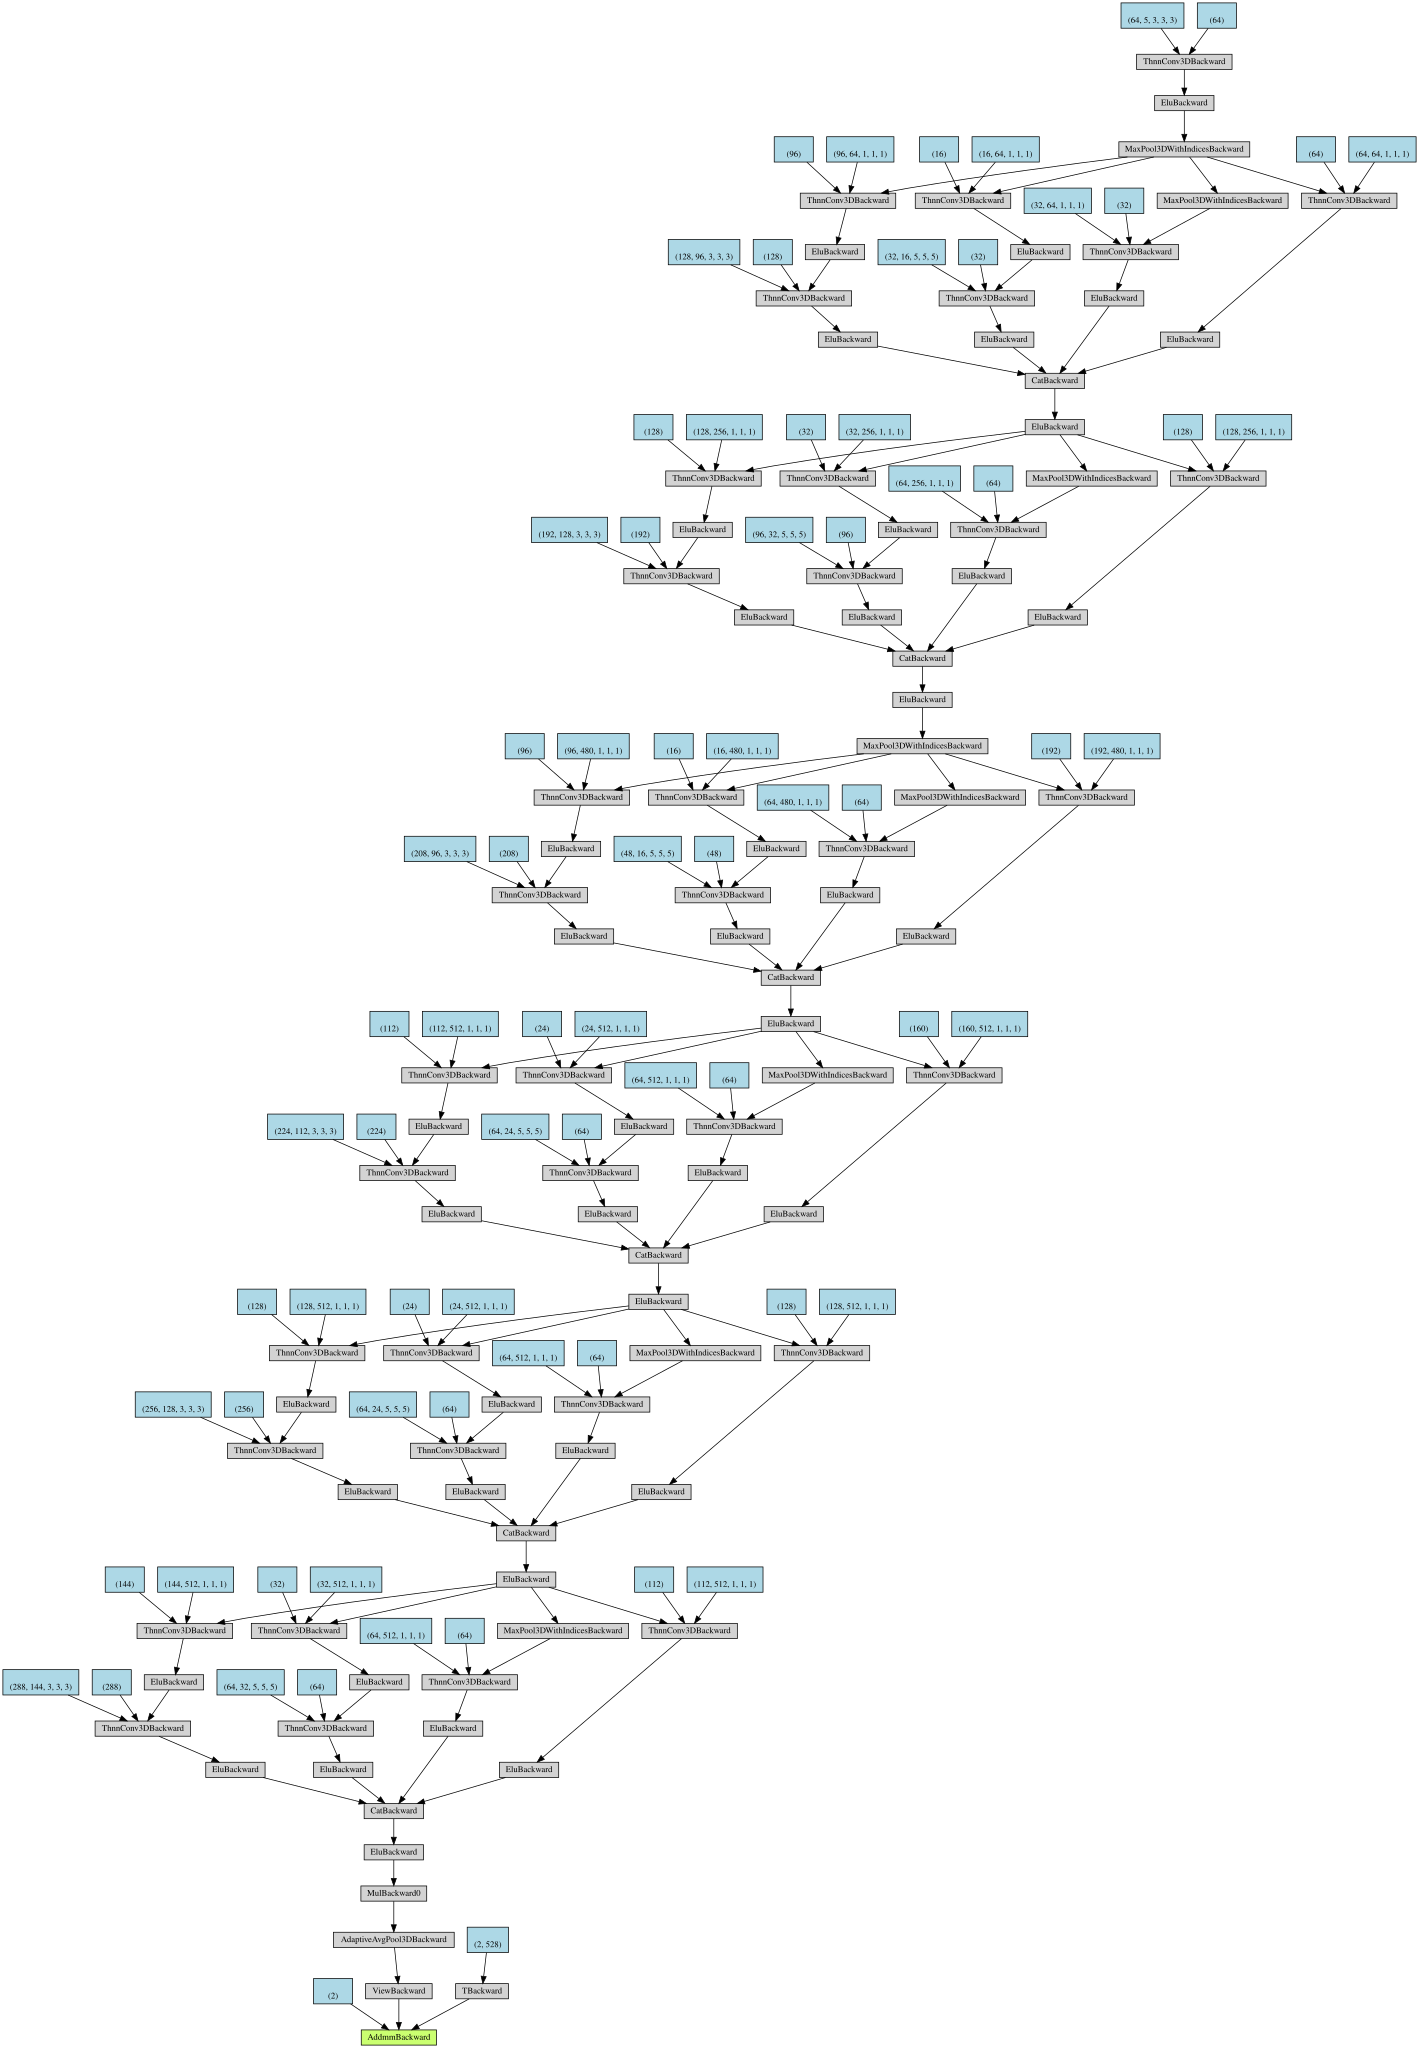

In [3]:
from torchviz import make_dot
make_dot(out)

## visualize all the performance of datasets

In [4]:
def custom_load_checkpoint(path):
    checkpoints= glob(os.path.abspath(path)+'/*')
    epochs, valid_loss, valid_acc = [], [], []
    modal = []
    paths = []
    for epoch_param in checkpoints:
        epoch = int(os.path.basename(epoch_param).split('_')[0].replace('params', ''))        
        vloss = float(os.path.basename(epoch_param).split('_')[6].replace('params', ''))  
        vacc = float(os.path.basename(epoch_param).split('_')[8].replace('params', ''))
        epochs.append(epoch)
        valid_loss.append(vloss)  
        valid_acc.append(vacc)
        modal.append(os.path.basename(os.path.dirname(epoch_param)).split('_')[1].replace('modal', ''))
        paths.append(epoch_param)
    metrics_all = pd.DataFrame(dict(epoch=epochs, validloss=valid_loss, validacc=valid_acc, modal=modal, path=paths))
    metrics_all.sort_values('validloss', inplace=True)
    return metrics_all

In [31]:
metrics_all = []
seeds = [1, 9, 999, 9999, 888]

for seed in seeds:
    for f in glob(f'results/models_Leukomalacia_seed{seed}_pure//Leu*modal*'):
    #for f in glob('results/models_Leukomalacia_gain//Leu*modal*'):
        if f.endswith('valid.csv'):
            df = pd.read_csv(f)
            df.loc[:, 'seed'] = seed
            metrics_all.append(df)
#     metrics = custom_load_checkpoint(f)
#     metrics.sort_values('epoch', inplace=True)
#     metrics_all.append(metrics)

In [32]:
best = []
for m, value in enumerate(metrics_all):
    if len(metrics_all[m].validacc.values)==0:
        continue
    best.append(metrics_all[m].iloc[np.argsort(metrics_all[m].validloss.values)[0],])
best = pd.concat(best, axis=1).transpose()
best.sort_values(['validloss'], inplace=True, ascending=True)
best = best.drop_duplicates(['modal', 'seed'], keep="first")
best_all = best
best_all

,Unnamed: 0,epoch,validloss,validacc,modal,path,seed
0,31,65,0.01039,0.82432,0,/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,11,39,0.01061,0.83784,"0,1,2",/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,17,53,0.01088,0.83784,"0,1",/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,15,55,0.01108,0.86486,0,/cluster/home/qinqian/PVL/results/models_Leuko...,9
0,18,45,0.01111,0.83784,"0,1,3",/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,22,58,0.01145,0.81081,"0,3",/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,18,50,0.01153,0.86036,"0,2",/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,13,33,0.01154,0.86036,"2,3,4",/cluster/home/qinqian/PVL/results/models_Leuko...,9
0,31,89,0.01166,0.79279,1,/cluster/home/qinqian/PVL/results/models_Leuko...,1
0,12,35,0.01179,0.83784,"0,1,2,3,4",/cluster/home/qinqian/PVL/results/models_Leuko...,1


## SCP the models from head1 to results/models_Leukomalacia_head1, and change to local path

## plot ROC and PR curves and barplots about AUCs

In [86]:
def replace_labels(x):
    x = x.replace('2', 'Axial ADC')    
    x = x.replace('1', 'Axial T2w')        
    x = x.replace('0', 'Axial T2 FLAIR')
    x = x.replace('3', 'Axial T1w')
    x = x.replace('4', 'T1w Saggital')
    x = x.replace(',', '+')
    return x
 
#too long labels ugly
#best.modal = best.modal.map(replace_labels)
labels = "0:Axial T2 FLAIR  1:Axial T2w  2:Axial ADC 3:Axial T1w 4:T1w Saggital"

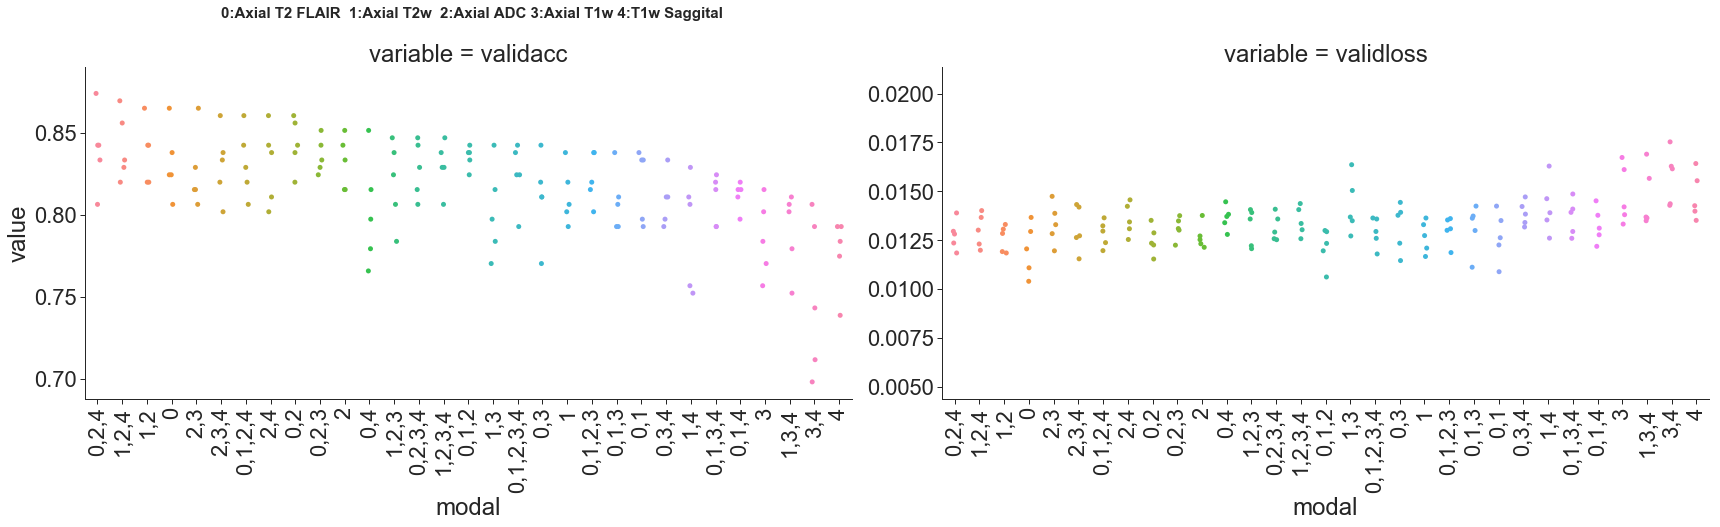

In [105]:
best_all.sort_values('validloss', inplace=True, ascending=False)
vis_valid_data = best_all.melt(id_vars=['modal', 'seed'], 
                         value_vars=['validacc', 'validloss'])
vis_valid_data.head()
plt.figure(figsize=(20, 9))
g = sns.catplot(x="modal", y="value", aspect=2, col="variable",
            hue="modal", sharey=False, data=vis_data,
            height=6)
g.axes[-1][0].text(5, 0.92,
                   labels, 
                   style='normal',fontweight='bold',fontsize=15,
                   bbox={'facecolor':'white', 'alpha':0.5, 'pad':10})
(g.set_xticklabels(rotation=90).despine())

for i in g.axes:
    for j in i:
        j.margins = [5,5,5,5]
# barplot below
# plt.subplot(2, 1, 1)
# ax = sns.barplot(x="modal", y="validacc", data=best_all,
#                  dodge=False, color='gray')
# sns.despine()
# plt.tick_params(axis='x', rotation=90, width=1)
# plt.ylim([0.5, 1])
# ax.text(32, 0.7, labels, style='normal',fontweight='bold',fontsize=12,
#         bbox={'facecolor':'white', 'alpha':0.5, 'pad':10})
# best_all.sort_values('validloss', inplace=True, ascending=True)
# plt.subplot(2, 1, 2)
# ax = sns.barplot(x="modal", y="validloss",
#                  data=best_all, dodge=False, color='gray')
# ax.text(32, 0.015, labels, style='normal',fontweight='bold',fontsize=15,
#          bbox={'facecolor':'white', 'alpha':0.5, 'pad':10})
# sns.despine()
# plt.tick_params(axis='x', rotation=90, width=1)
# plt.ylim([0, 0.04])
# plt.tight_layout()
g.savefig('results/FigS2.pdf', height=12) # weird axis labels

In [3]:
test_bids = pd.read_csv('results/seed1_test.csv', index_col=0)
train_bids = pd.read_csv('results/seed1_train.csv', index_col=0)
valid_bids = pd.read_csv('results/seed1_valid.csv', index_col=0)
np.intersect1d(valid_bids.index, train_bids.index)

array([], dtype=int64)

In [5]:
print(test_bids.shape, train_bids.shape, valid_bids.shape)

(344, 17) (560, 17) (241, 17)


/home/qinqian/.local/lib/python3.6/site-packages/scipy-1.0.1-py3.6-linux-x86_64.egg/scipy/stats/stats.py:1706: FutureWarning:

Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.



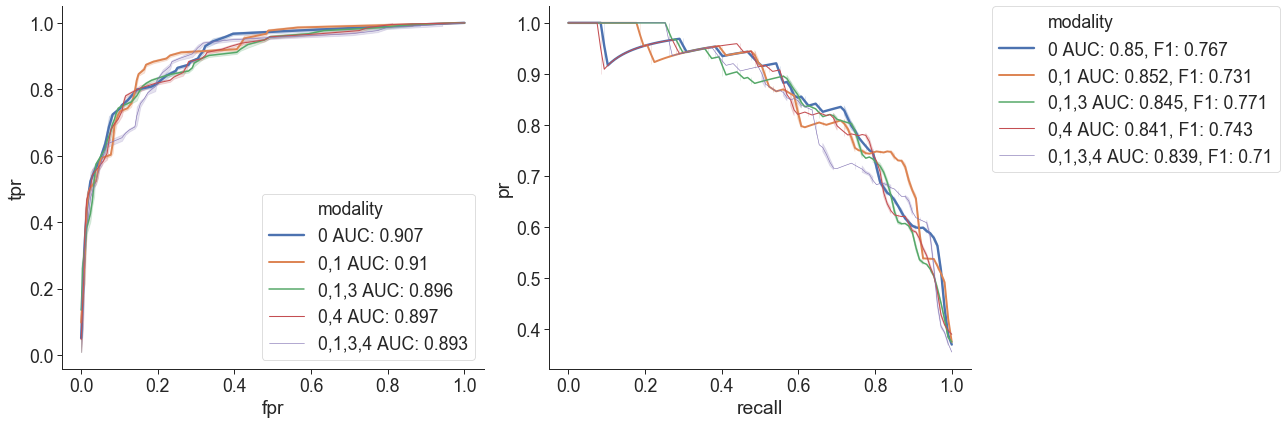

In [14]:
best_all.sort_values('validloss', inplace=True)

results_roc = []
results_pr = []

for m, p in zip(best_all.modal[:5], best_all.path[:5]):
    if os.path.exists(os.path.dirname(p) + "_test.csv"):
        df = pd.read_csv(os.path.dirname(p) + "_test.csv")
        auc = round(roc_auc_score(df.loc[:, "labels"], df.loc[:, 'outputs']), 3)
        pr_auc = round(average_precision_score(df.loc[:, "labels"], df.loc[:, 'outputs']), 3)
        f1 = round(f1_score(df.loc[:, "labels"], df.loc[:, "predict"]), 3)
        fpr, tpr, _ = roc_curve(df.loc[:, "labels"], df.loc[:, 'outputs'])
        pr, recall, _ = precision_recall_curve(df.loc[:, "labels"], df.loc[:, 'outputs'])     
        results_roc.append(pd.DataFrame(dict(fpr=fpr, tpr=tpr, modality=[m + " AUC: %s" % auc] * len(tpr))))
        results_pr.append(pd.DataFrame(dict(pr=pr, recall=recall, modality=[m + " AUC: %s, F1: %s" % (pr_auc, f1)] * len(pr))))
    else:
        print(p)

results_roc = pd.concat(results_roc, axis=0)
results_pr =  pd.concat(results_pr, axis=0)

plt.figure(figsize=(18, 6))
plt.subplot(1, 2, 1)
sns.lineplot(x="fpr", y="tpr", size="modality", hue="modality", data=results_roc, dashes=False, legend="brief")
plt.subplot(1, 2, 2)
sns.lineplot(x="recall", y="pr", size="modality", hue="modality", data=results_pr, dashes=False, legend="full")
plt.legend(bbox_to_anchor=(1.05, 1), loc=0, borderaxespad=0.)
plt.tight_layout()
sns.despine()

In [29]:
performances = []
modal = []
for m, p in zip(best_all.modal, best_all.path):
    if os.path.exists(os.path.dirname(p) + "_test.csv"):
        modal.append(m)
        df = pd.read_csv(os.path.dirname(p) + "_test.csv")
        auc = round(roc_auc_score(df.loc[:, "labels"], df.loc[:, 'outputs']), 2)
        pr_auc = round(average_precision_score(df.loc[:, "labels"], df.loc[:, 'outputs']), 2)
        f1 = round(f1_score(df.loc[:, "labels"], df.loc[:, "predict"]), 2)
        acc = (df.loc[:, "labels"] == df.loc[:, "predict"]).mean()
        performances.append(np.array([auc, pr_auc, f1, acc]))
    else:
        print(p)
    
performances = np.vstack(performances)
performances = pd.DataFrame(performances, index=modal, columns=['ROCAUC', 'PRAUC', 'F1', 'Accuracy'])

/home/qinqian/.local/lib/python3.6/site-packages/scipy-1.0.1-py3.6-linux-x86_64.egg/scipy/stats/stats.py:1706: FutureWarning:

Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.

/home/qinqian/.local/lib/python3.6/site-packages/ipykernel_launcher.py:37: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.

/home/qinqian/.local/lib/python3.6/site-packages/ipykernel_launcher.py:47: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



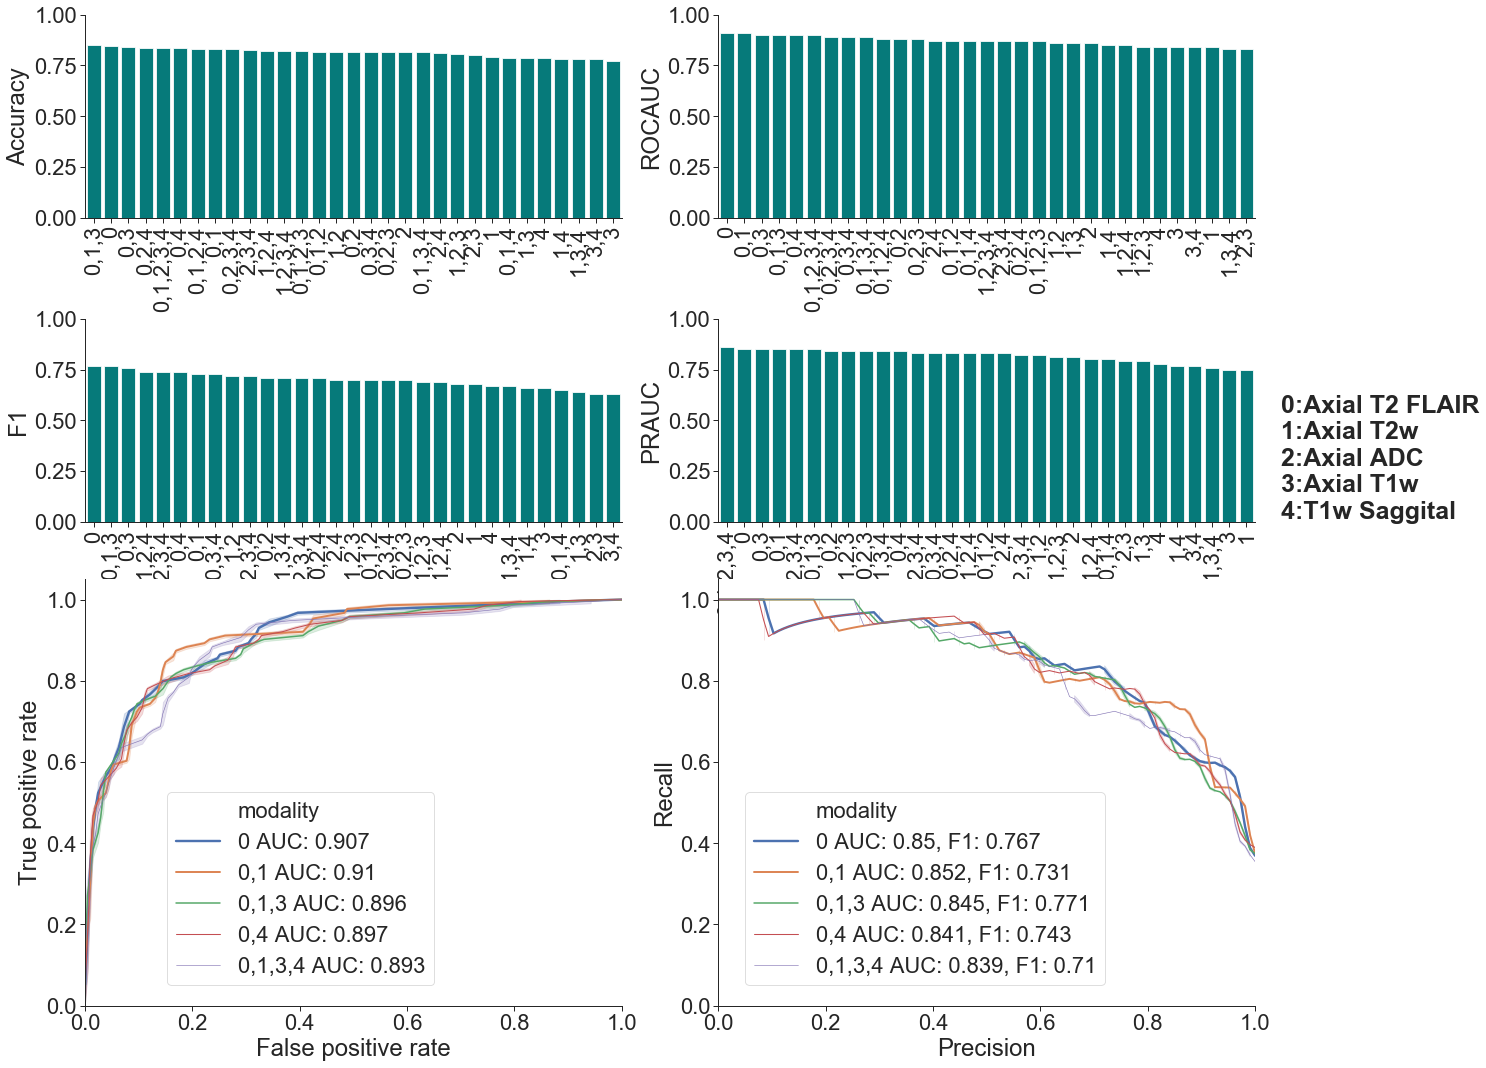

In [52]:
plt.figure(figsize=(25, 16))

from matplotlib import gridspec
gs = gridspec.GridSpec(2, 2, wspace=0.18, hspace=0.5, bottom=0.5, top=0.94, left=0.1, right=0.75)

def plot_metrics(x, performances):
    performances = performances.sort_values(x, ascending=False)    
    ax = sns.barplot(x=performances.index, y=x, data=performances, 
                     dodge=False, color="teal", n_boot=500, saturation=0.9)

    sns.despine()
    plt.tick_params(axis='x', rotation=90, width=1)
    plt.ylim([0, 1])
    return ax

plt.subplot(gs[0, 0])
plot_metrics('Accuracy', performances)
plt.subplot(gs[0, 1])
plot_metrics('ROCAUC', performances)
plt.subplot(gs[1, 0])
plot_metrics('F1', performances)
ax = plt.subplot(gs[1, 1])
ax = plot_metrics('PRAUC', performances)
ax.text(32, 0.015, labels, style='normal',fontweight='bold',fontsize=25,
        bbox={'facecolor':'white', 'alpha':0.5, 'pad':10})

gs = gridspec.GridSpec(1, 2, wspace=0.18, hspace=0.5, bottom=0.08, top=0.45, left=0.1, right=0.75)

plt.subplot(gs[0, 0])
sns.lineplot(x="fpr", y="tpr", size="modality", hue="modality", data=results_roc, dashes=False, legend="brief")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.ylim([0, 1.05])
plt.xlim([0, 1])
sns.despine()
plt.legend(bbox_to_anchor=(0.65, 0.5), loc=0, borderaxespad=0.)
plt.tight_layout()
plt.subplot(gs[0, 1])
sns.lineplot(x="recall", y="pr", size="modality", hue="modality", data=results_pr, dashes=False, legend="brief")
plt.xlabel("Precision")
plt.ylabel("Recall")
plt.ylim([0, 1.05])
plt.xlim([0, 1])

sns.despine()
plt.legend(bbox_to_anchor=(0.72, 0.5), loc=0, borderaxespad=0.)
plt.tight_layout()
plt.savefig("results/Fig2.pdf")

## Select the best model

In [19]:
best_all.iloc[0, :].path

'/data1/qinqian/MRI/01_PVL_AI/scripts/models/pytorch/results/models_Leukomalacia_pure/Leukomalacia_modal0_class_models_initiallr0.000170_batch32_drop0.5/params42_dataiter_16_currentlr_5.6661e-05_validloss_0.01069_validacc_0.85909_train_loss_0.00389_train_acc_0.96875.ckpt'

In [ ]:
best_all